# M2: Power-law analysis of the degree distribution

**Paper section covered:** 4.1 (Power-Law Fitting of the Degree Distribution, Fig. 3)

## Goal
1. **Reproduce** the paper's fit exactly: a power law P(k) ~ k^(-gamma) with gamma about 1.89.
2. **Understand and test** what that number is supposed to mean (the "anomalous regime", gamma <= 2).
3. **Check the recipe**: is the way the paper fits a power law statistically sound, and does the conclusion survive a proper analysis?

## What the paper claims
- The degree distribution "closely aligns with" a power law with exponent **gamma = 1.89** (Fig. 3).
- Since gamma <= 2, the USFN is in the **anomalous regime**, characterised by a biggest hub whose degree grows linearly with network size (k_max ~ N), a hub-and-spoke configuration, and an average path length independent of network size.
- Such hub-dominated networks are vulnerable to targeted attacks (tested later, in M5 and M6).

## Plan of this notebook
| Part | Question |
|---|---|
| A | Which fitting recipe gives 1.89? Reproduce Fig. 3. |
| B | What does gamma <= 2 imply, and is that physically possible for a network with 541 nodes? |
| C | Is the recipe sound? Compare estimators, validate on synthetic data, test sensitivity to the tail cut-off, bootstrap uncertainty, goodness of fit, and competing distributions. |
| D | Verdict on each of the paper's claims. |

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import powerlaw
from scipy.special import zeta

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import usfn
import powerlaw_tools as pt

warnings.filterwarnings("ignore", category=RuntimeWarning)       # powerlaw package prints harmless divide warnings
warnings.filterwarnings("ignore", category=UserWarning, module="powerlaw")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
BLUE, RED, GREEN, ORANGE, GREY = "#3b6ea5", "#c05746", "#4d8f5b", "#d99a2b", "#777777"
SEED = 2025

airports, routes = usfn.load_openflights()
G = usfn.build_country_network(airports, routes)
x = np.array([d for _, d in G.degree()])                  # degree sequence, 541 integers
N = len(x)
assert N == 541 and x.max() == 153
print(f"degree sequence: n = {N}, min = {x.min()}, median = {np.median(x):.0f}, max = {x.max()}")

degree sequence: n = 541, min = 1, median = 3, max = 153


## Part A. Reproducing the paper's fit

### A1. Which recipe gives 1.89?
The paper does not say how the exponent was estimated. We tested the usual candidates (see the table in Part C1) and exactly one reproduces **1.89**: the Python `powerlaw` package called with its defaults, `powerlaw.Fit(degrees)`. That call
1. treats the data as **continuous** (even though degrees are integers),
2. chooses the tail start **x_min** automatically by minimising the Kolmogorov-Smirnov (KS) distance between data and fit,
3. estimates the exponent by **maximum likelihood** on the tail, alpha = 1 + n / sum(ln(x / x_min)).

We run it, and also run our own from-scratch implementation of the same recipe (`src/powerlaw_tools.py`) to confirm we understand exactly what it does.

In [2]:
fit_pkg = powerlaw.Fit(x, verbose=False)                      # the paper's recipe (package defaults)
fit_own = pt.fit(x, kind="continuous")                         # our implementation of the same recipe

pd.DataFrame([
    ("alpha (gamma)",  1.89, round(fit_pkg.power_law.alpha, 4), round(fit_own["alpha"], 4)),
    ("x_min",          None, fit_pkg.xmin,                       fit_own["xmin"]),
    ("tail size n_tail", None, int(fit_pkg.n_tail),              fit_own["n_tail"]),
    ("KS distance D",  None, round(fit_pkg.power_law.D, 4),      round(fit_own["ks"], 4)),
    ("std. error of alpha (package)", None, round(fit_pkg.power_law.sigma, 4), None),
], columns=["quantity", "paper", "powerlaw package", "our implementation"]).style.hide(axis="index").format(na_rep="not reported")

quantity,paper,powerlaw package,our implementation
alpha (gamma),1.890000,1.893900,1.893900
x_min,not reported,2.000000,2.000000
tail size n_tail,not reported,387.000000,387.000000
KS distance D,not reported,0.080400,0.080400
std. error of alpha (package),not reported,0.045400,not reported


**The paper's number reproduces: gamma = 1.894 (paper: 1.89), with x_min = 2.** Our own implementation agrees with the package to all printed digits, so we know exactly what the paper's fit is: a continuous-data MLE on the 387 airports (72%) with degree >= 2.

### A2. Reproducing Fig. 3
Fig. 3 shows the empirical degree distribution on log-log axes with the fitted line. The package's `plot_pdf` bins the data logarithmically, which is why the paper's y-axis reaches below the smallest possible raw P(k) = 1/541.

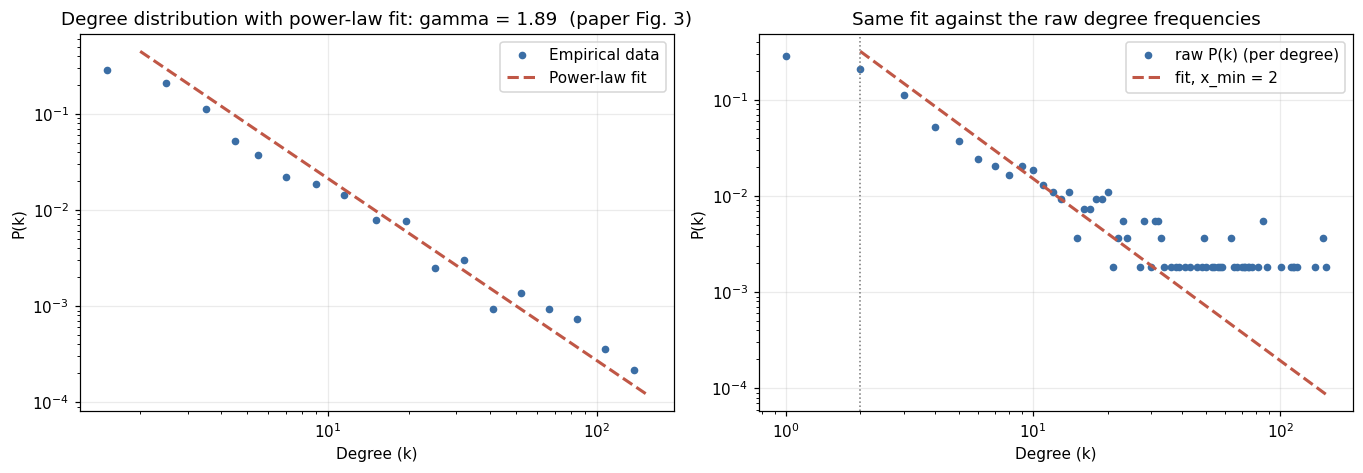

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax = axes[0]                                                    # paper-style figure
fit_pkg.plot_pdf(ax=ax, original_data=True, color=BLUE, marker="o", linestyle="", markersize=4, label="Empirical data")
fit_pkg.power_law.plot_pdf(ax=ax, color=RED, linestyle="--", linewidth=2, label=f"Power-law fit")
ax.set_xlabel("Degree (k)"); ax.set_ylabel("P(k)")
ax.set_title(f"Degree distribution with power-law fit: gamma = {fit_pkg.power_law.alpha:.2f}  (paper Fig. 3)")
ax.legend()

ax = axes[1]                                                    # same fit, raw (un-binned) points for honesty
cnt = Counter(x); ks = np.array(sorted(cnt)); pk = np.array([cnt[k] for k in ks]) / N
ax.loglog(ks, pk, "o", color=BLUE, ms=4, label="raw P(k) (per degree)")
kk = np.logspace(np.log10(fit_pkg.xmin), np.log10(x.max()), 50)
C = (fit_pkg.alpha - 1) / fit_pkg.xmin * (fit_pkg.n_tail / N)   # continuous pdf scaled to the tail's share of nodes
ax.loglog(kk, C * (kk / fit_pkg.xmin) ** (-fit_pkg.alpha), "--", color=RED, lw=2, label=f"fit, x_min = {int(fit_pkg.xmin)}")
ax.axvline(fit_pkg.xmin, color=GREY, ls=":", lw=1)
ax.set_xlabel("Degree (k)"); ax.set_ylabel("P(k)"); ax.set_title("Same fit against the raw degree frequencies"); ax.legend()
plt.tight_layout(); plt.show()

The left panel is the paper's figure. Visually the empirical points do follow a straight line over about two decades, which is presumably why the paper concluded the fit is good. Two things deserve notice: the line only describes the tail (k >= 2), and a straight-looking log-log plot is notoriously weak evidence for a power law. Part C tests it properly. (In the right panel the raw points flatten at 1/541 for high degrees: each large degree occurs in only one airport, so this band is sampling noise, another reason raw log-log plots mislead.)

## Part B. What does gamma <= 2 imply?

The paper (following Barabasi's *Network Science*) places gamma <= 2 in the **anomalous regime**:

| gamma | Regime | Consequence (in the N -> infinity limit) |
|---|---|---|
| gamma <= 2 | anomalous | mean degree and largest hub diverge; the biggest hub grows as N^(1/(gamma-1)), *faster* than the network itself |
| 2 < gamma < 3 | scale-free | mean degree finite, variance diverges, hubs dominate |
| gamma > 3 | random-like | hubs are small, behaves like a random network |

For gamma = 1.89 the hub scales as N^(1/0.89) = N^1.12, which would exceed the network size. In a simple graph a node can have at most N - 1 connections, so a true gamma < 2 network *must* have a **structural cutoff**: its largest hub is capped by N - 1, and the paper's "k_max ~ N" is the capped version. We can check whether our network behaves like a pure power law at the top of the distribution by asking a concrete question: **if the 387 tail airports really followed a pure power law with these exponents, how many would have more connections than there are airports?**

In [4]:
rng = np.random.default_rng(SEED)
n_tail, xmin = 387, 2

def p_exceed(alpha, k):                      # P(degree >= k) under a discrete power law with x_min = 2
    return zeta(alpha, k) / zeta(alpha, xmin)

rows = []
for label, alpha in [("paper's estimate (continuous MLE)", fit_pkg.alpha), ("discrete MLE (Part C)", pt.fit(x, "discrete")["alpha"])]:
    sims = np.array([pt.sample_discrete(n_tail, alpha, xmin, rng).max() for _ in range(2000)])
    rows.append({"model": label, "gamma": round(alpha, 3),
                 "P(a tail airport has degree >= 541)": f"{p_exceed(alpha, N):.4f}",
                 "expected # such airports": round(n_tail * p_exceed(alpha, N), 1),
                 "P(max degree >= 541)": f"{(sims >= N).mean():.1%}",
                 "median simulated max degree": int(np.median(sims))})
res_b = pd.DataFrame(rows); display(res_b)
print(f"Observed: maximum degree = {x.max()} (ATL), i.e. {x.max() / (N - 1):.0%} of the largest possible value N - 1 = {N - 1}.")

,model,gamma,P(a tail airport has degree >= 541),expected # such airports,P(max degree >= 541),median simulated max degree
0,paper's estimate (continuous MLE),1.894,0.0053,2.1,87.8%,2004
1,discrete MLE (Part C),1.732,0.0137,5.3,99.7%,8327


Observed: maximum degree = 153 (ATL), i.e. 28% of the largest possible value N - 1 = 540.


**Reading this.** A pure power law with the paper's exponent would produce *at least one airport with more connections than there are airports* (impossible) in 88% of simulated networks (99.7% with the discrete exponent), with a median largest degree in the thousands, far beyond the observed 153. So the real distribution must bend down at the top: the biggest hub (ATL, 153) is far smaller than a pure power law predicts. This is exactly what a **finite-size cutoff** looks like. It does not contradict "hub-dominated" (153 against a typical degree of 3 is extreme), but it does mean the *pure* power law, and therefore the asymptotic "anomalous regime" label, cannot literally hold for this network. A single 541-node snapshot also cannot test "k_max grows linearly with N", because that needs networks of different sizes (we compare countries in M10).

## Part C. Is the recipe sound?

The paper's fit has four weaknesses we can test: (i) it uses a **continuous** estimator on integer data, (ii) the tail start x_min is chosen automatically and never reported, (iii) there is **no uncertainty** on gamma, and (iv) there is **no goodness-of-fit test** and no comparison with other heavy-tailed distributions. Clauset, Shalizi and Newman (2009) give the standard remedy for each; we implement it in `src/powerlaw_tools.py`.

### C1. Many ways to estimate gamma on the same data
The same degree sequence gives very different exponents depending on the method. This is why the method must be stated.

In [5]:
d_disc = pt.fit(x, "discrete")
ux = np.unique(x); pk_all = np.array([cnt[k] for k in ux]) / N

# log-binned least squares on the density
edges = np.unique(np.logspace(0, np.log10(x.max() + 1), 15).astype(int))
h, e = np.histogram(x, bins=edges, density=True); mid = np.sqrt(e[:-1] * e[1:]); m = h > 0
ols_logbin = -np.polyfit(np.log(mid[m]), np.log(h[m]), 1)[0]
ols_raw = -np.polyfit(np.log(ux), np.log(pk_all), 1)[0]
srt = np.sort(x); ccdf = 1 - np.arange(N) / N
ols_ccdf = 1 - np.polyfit(np.log(srt), np.log(ccdf), 1)[0]

est = pd.DataFrame([
    ("Least squares on raw log P(k) vs log k",                   ols_raw,                         "biased (small counts, unweighted)"),
    ("Least squares on log-binned density",                      ols_logbin,                      "depends on bin choice"),
    ("Least squares on the CCDF (1 - slope)",                    ols_ccdf,                        "biased, errors are correlated"),
    ("Discrete MLE, x_min = 1 (all data)",                       pt.alpha_discrete(x, 1),         "uses whole distribution"),
    ("Discrete MLE, x_min = 2 (same tail as paper)",             pt.alpha_discrete(x, 2),         "correct estimator for integers"),
    ("Discrete MLE, x_min chosen by KS (Clauset et al.)",        d_disc["alpha"],                 f"x_min = {int(d_disc['xmin'])}"),
    ("Continuous MLE, x_min chosen by KS  (THE PAPER'S RECIPE)", fit_pkg.alpha,                   "assumes continuous data"),
], columns=["estimator", "gamma", "comment"])
est["gamma <= 2 ?"] = np.where(est.gamma <= 2, "yes", "no")
est.style.hide(axis="index").format({"gamma": "{:.3f}"})

estimator,gamma,comment,gamma <= 2 ?
Least squares on raw log P(k) vs log k,1.028,"biased (small counts, unweighted)",yes
Least squares on log-binned density,1.566,depends on bin choice,yes
Least squares on the CCDF (1 - slope),1.745,"biased, errors are correlated",yes
"Discrete MLE, x_min = 1 (all data)",1.561,uses whole distribution,yes
"Discrete MLE, x_min = 2 (same tail as paper)",1.732,correct estimator for integers,yes
"Discrete MLE, x_min chosen by KS (Clauset et al.)",1.732,x_min = 2,yes
"Continuous MLE, x_min chosen by KS (THE PAPER'S RECIPE)",1.894,assumes continuous data,yes


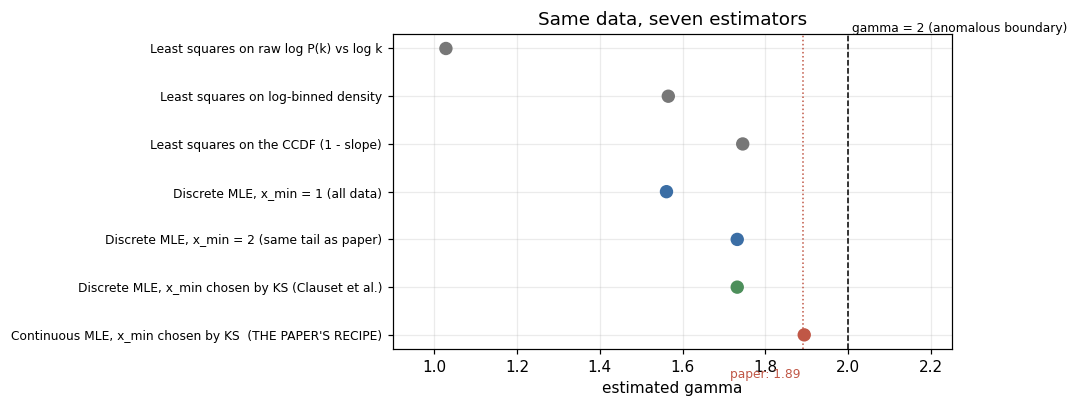

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ypos = np.arange(len(est))[::-1]
colors = [GREY, GREY, GREY, BLUE, BLUE, GREEN, RED]
ax.scatter(est.gamma, ypos, c=colors, s=60, zorder=3)
ax.axvline(2.0, color="black", ls="--", lw=1); ax.text(2.01, ypos.max() + 0.35, "gamma = 2 (anomalous boundary)", fontsize=8)
ax.axvline(1.89, color=RED, ls=":", lw=1); ax.text(1.885, -0.9, "paper: 1.89", fontsize=8, ha="right", color=RED)
ax.set_yticks(ypos); ax.set_yticklabels(est.estimator, fontsize=8); ax.set_xlabel("estimated gamma")
ax.set_title("Same data, seven estimators"); ax.set_xlim(0.9, 2.25)
plt.tight_layout(); plt.show()

**Reading this.** Ordinary least squares on a log-log plot, the easiest thing to do, gives anything from 1.0 to 1.75 depending on how the data are binned, because it is a poor estimator for sparse, discrete tail data. The maximum-likelihood estimators are more consistent (1.56 to 1.89). The paper's recipe gives the **highest of all seven estimates**. The next section shows why.

### C2. Validating the estimators on data where the truth is known
We draw synthetic degree sequences from a *discrete* power law with known exponent (n = 541, x_min = 2, the same size and tail start as ours) and see what each recipe recovers. If the continuous recipe has a bias, it will show here.

true gamma,continuous recipe: mean,continuous: bias,continuous: sd,discrete MLE: mean,discrete: bias,discrete: sd
1.700,1.800,0.100,0.074,1.710,0.010,0.043
2.000,2.166,0.166,0.114,2.006,0.006,0.048
2.500,2.865,0.365,0.272,2.508,0.008,0.081
3.000,3.659,0.659,0.463,2.988,-0.012,0.096


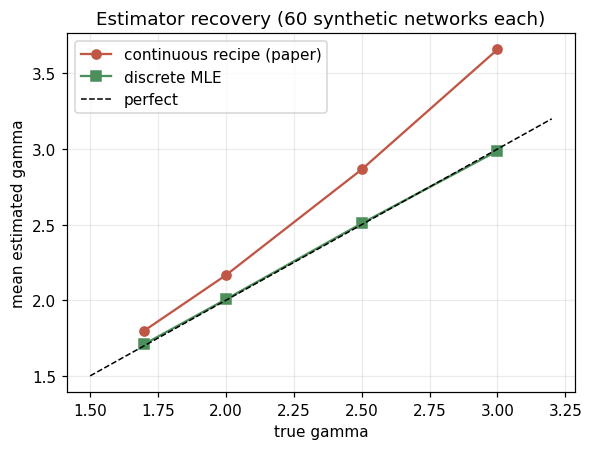

In [7]:
rng = np.random.default_rng(SEED)
R = 60
rows = []
for a_true in [1.7, 2.0, 2.5, 3.0]:
    cont, disc = [], []
    for _ in range(R):
        d = pt.sample_discrete(N, a_true, 2, rng)
        cont.append(pt.fit(d, "continuous")["alpha"])         # the paper's recipe
        disc.append(pt.fit(d, "discrete")["alpha"])           # discrete MLE, x_min by KS
    rows.append({"true gamma": a_true,
                 "continuous recipe: mean": np.mean(cont), "continuous: bias": np.mean(cont) - a_true, "continuous: sd": np.std(cont),
                 "discrete MLE: mean": np.mean(disc), "discrete: bias": np.mean(disc) - a_true, "discrete: sd": np.std(disc)})
valid = pd.DataFrame(rows)
display(valid.style.hide(axis="index").format(precision=3))

fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.plot(valid["true gamma"], valid["continuous recipe: mean"], "o-", color=RED, label="continuous recipe (paper)")
ax.plot(valid["true gamma"], valid["discrete MLE: mean"], "s-", color=GREEN, label="discrete MLE")
ax.plot([1.5, 3.2], [1.5, 3.2], color="black", ls="--", lw=1, label="perfect")
ax.set_xlabel("true gamma"); ax.set_ylabel("mean estimated gamma"); ax.set_title(f"Estimator recovery ({R} synthetic networks each)"); ax.legend()
plt.tight_layout(); plt.show()

**Reading this.** The discrete MLE recovers the true exponent essentially without bias. The continuous recipe used by the paper **overestimates gamma**, and the error grows with gamma (+0.10 at gamma = 1.7, +0.17 at 2.0, +0.37 at 2.5, +0.66 at 3.0), while the discrete MLE is within 0.02 everywhere. The cause is that integer data with many ties at small degrees violate the continuous model. So, on the same tail, the right estimate for this network is the **discrete 1.73, not 1.89**. The correction goes *further into* the gamma < 2 region, so it does not weaken the paper's regime classification on this point, but the number 1.89 itself is an artefact of the recipe.

### C3. How sensitive is gamma to the choice of tail start x_min?
The estimate is computed only on degrees >= x_min. We scan x_min and watch the exponent, the KS distance, and how much data remains.

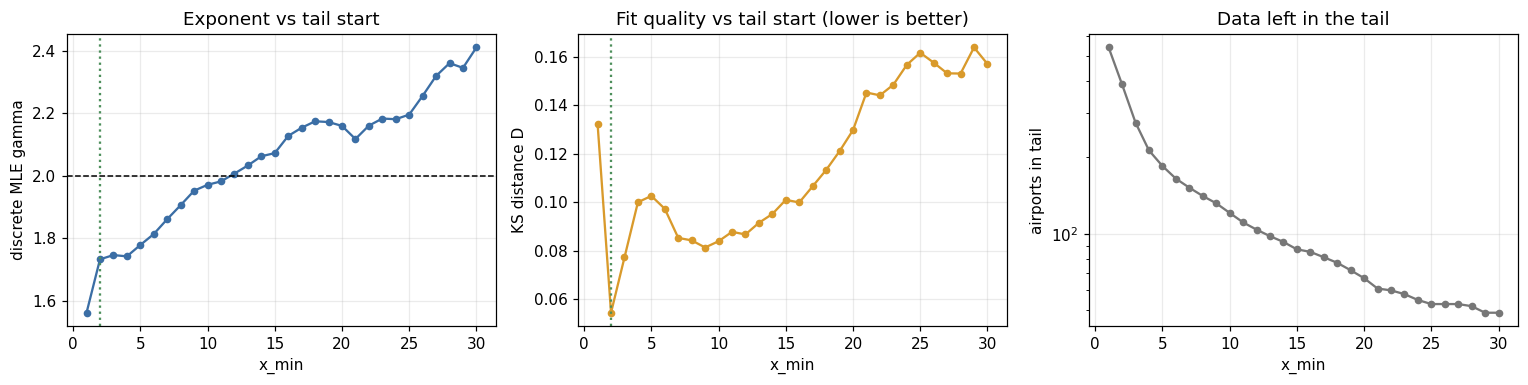

x_min,gamma,n_tail,KS
1,1.561,541,0.132
2,1.732,387,0.054
3,1.746,274,0.077
4,1.742,213,0.100
5,1.778,185,0.103
6,1.813,165,0.097
8,1.905,141,0.084
10,1.971,121,0.084
15,2.072,87,0.101
20,2.159,67,0.130


gamma first exceeds 2 at x_min = 12, where 104 airports (19%) remain in the tail


In [8]:
scan = []
for xm in range(1, 31):
    a = pt.alpha_discrete(x, xm)
    scan.append({"x_min": xm, "gamma": a, "n_tail": int((x >= xm).sum()), "KS": pt._ks_discrete(x[x >= xm], xm, a)})
scan = pd.DataFrame(scan)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(scan.x_min, scan.gamma, "o-", color=BLUE, ms=4); axes[0].axhline(2, color="black", ls="--", lw=1)
axes[0].axvline(d_disc["xmin"], color=GREEN, ls=":"); axes[0].set_xlabel("x_min"); axes[0].set_ylabel("discrete MLE gamma"); axes[0].set_title("Exponent vs tail start")
axes[1].plot(scan.x_min, scan.KS, "o-", color=ORANGE, ms=4); axes[1].axvline(d_disc["xmin"], color=GREEN, ls=":")
axes[1].set_xlabel("x_min"); axes[1].set_ylabel("KS distance D"); axes[1].set_title("Fit quality vs tail start (lower is better)")
axes[2].semilogy(scan.x_min, scan.n_tail, "o-", color=GREY, ms=4); axes[2].set_xlabel("x_min"); axes[2].set_ylabel("airports in tail"); axes[2].set_title("Data left in the tail")
plt.tight_layout(); plt.show()
display(scan[scan.x_min.isin([1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30])].style.hide(axis="index").format({"gamma": "{:.3f}", "KS": "{:.3f}"}))
first_above = scan[scan.gamma > 2].iloc[0]
x_cross, n_cross = int(first_above.x_min), int(first_above.n_tail)
print(f"gamma first exceeds 2 at x_min = {x_cross}, where {n_cross} airports ({n_cross / N:.0%}) remain in the tail")

**Reading this.** The exponent is *not* a stable property of the network: it rises steadily as x_min increases and crosses 2 at x_min = 12, where 104 airports (19%) remain. The KS distance is smallest at x_min = 2, which is why that is selected, but the data cannot pin the exponent down. Any claim "gamma < 2" therefore needs an uncertainty statement. That is the next test.

### C4. Uncertainty: bootstrap confidence intervals
We resample the 541 degrees with replacement 1,000 times and refit each time, *including* re-selecting x_min, so that tail-selection uncertainty is included. We do this for both the paper's recipe and the discrete MLE.

recipe,point estimate,bootstrap median,95% CI low,95% CI high,P(gamma <= 2),median x_min
discrete MLE (correct for integers),1.732,1.738,1.675,2.354,0.913,2.000
continuous recipe (paper),1.894,1.914,1.811,2.388,0.763,2.000


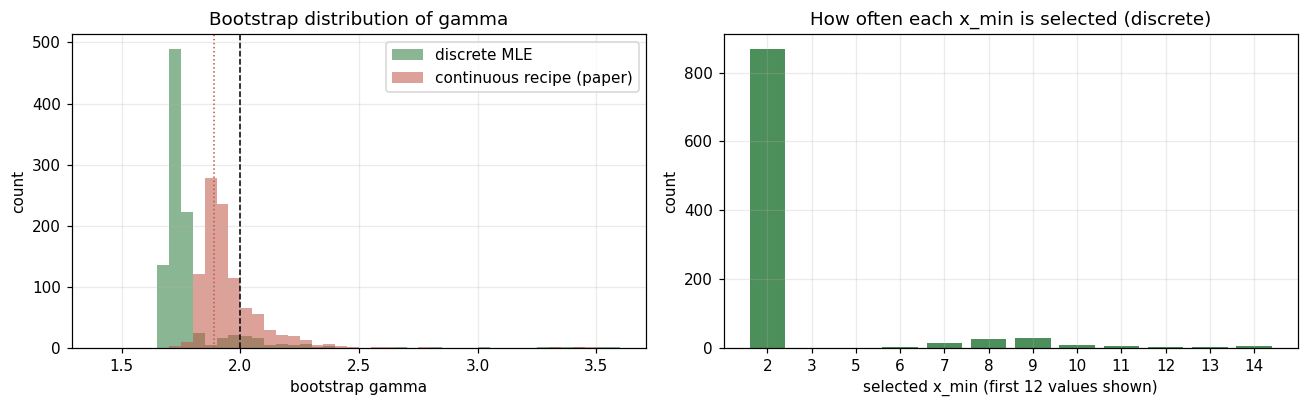

In [9]:
B = 1000
boot_d = pt.bootstrap_alpha(x, "discrete", B, seed=SEED)
boot_c = pt.bootstrap_alpha(x, "continuous", B, seed=SEED)

def summ(name, b, point):
    lo, med, hi = np.percentile(b[:, 0], [2.5, 50, 97.5])
    return {"recipe": name, "point estimate": point, "bootstrap median": med, "95% CI low": lo, "95% CI high": hi,
            "P(gamma <= 2)": (b[:, 0] <= 2).mean(), "median x_min": np.median(b[:, 1])}

ci = pd.DataFrame([summ("discrete MLE (correct for integers)", boot_d, d_disc["alpha"]),
                   summ("continuous recipe (paper)", boot_c, fit_pkg.alpha)])
display(ci.style.hide(axis="index").format(precision=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(1.4, 3.6, 45)
axes[0].hist(boot_d[:, 0], bins=bins, alpha=0.65, color=GREEN, label="discrete MLE")
axes[0].hist(boot_c[:, 0], bins=bins, alpha=0.55, color=RED, label="continuous recipe (paper)")
axes[0].axvline(2, color="black", ls="--", lw=1); axes[0].axvline(1.89, color=RED, ls=":", lw=1)
axes[0].set_xlabel("bootstrap gamma"); axes[0].set_ylabel("count"); axes[0].set_title("Bootstrap distribution of gamma"); axes[0].legend()

vals_d, cnts_d = np.unique(boot_d[:, 1], return_counts=True)
axes[1].bar(vals_d.astype(int).astype(str)[:12], cnts_d[:12], color=GREEN)
axes[1].set_xlabel("selected x_min (first 12 values shown)"); axes[1].set_ylabel("count"); axes[1].set_title("How often each x_min is selected (discrete)")
plt.tight_layout(); plt.show()

**Reading this.** Under the discrete estimator gamma has a 95% interval of about [1.68, 2.35], and 91% of resamples are below 2. For the paper's recipe the interval is about [1.81, 2.39] and 76% of resamples are below 2. Both intervals have a long upper tail that reaches 2.35 to 2.4, so the regime boundary (2) lies inside the range of values the data cannot exclude. "gamma = 1.89" is a point estimate with substantial uncertainty; the paper reports none.

### C5. Goodness of fit: could this data have come from a power law at all?
A good-looking line is not a test. The standard test (Clauset et al., Section 4.1) generates many synthetic datasets from the fitted power law (keeping the non-tail part from the empirical data), refits each one the same way, and asks how often the synthetic data fit *worse* than the real data. The **p-value** is that fraction; small p (below 0.1) means the power law is rejected.

empirical KS distance D = 0.0544
synthetic KS distances: median 0.0251, 95th percentile 0.0386, max 0.0554
goodness-of-fit p-value = 0.001   (fraction of 1000 synthetic power laws that fit worse than the real data)
Decision at the usual 0.1 threshold: power law is REJECTED


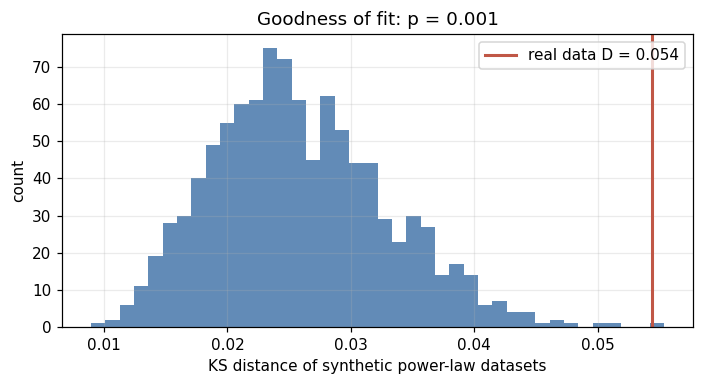

In [10]:
gof = pt.gof_bootstrap(x, "discrete", n_boot=1000, seed=SEED)
D_emp = gof["fit"]["ks"]
print(f"empirical KS distance D = {D_emp:.4f}")
print(f"synthetic KS distances: median {np.median(gof['ks_null']):.4f}, 95th percentile {np.percentile(gof['ks_null'], 95):.4f}, max {gof['ks_null'].max():.4f}")
print(f"goodness-of-fit p-value = {gof['p']:.3f}   (fraction of 1000 synthetic power laws that fit worse than the real data)")
print("Decision at the usual 0.1 threshold:", "power law is NOT rejected" if gof["p"] > 0.1 else "power law is REJECTED")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(gof["ks_null"], bins=40, color=BLUE, alpha=0.8)
ax.axvline(D_emp, color=RED, lw=2, label=f"real data D = {D_emp:.3f}")
ax.set_xlabel("KS distance of synthetic power-law datasets"); ax.set_ylabel("count"); ax.set_title(f"Goodness of fit: p = {gof['p']:.3f}"); ax.legend()
plt.tight_layout(); plt.show()

### C6. Competing distributions
Finally we ask whether other distributions describe the tail better. We fit three alternatives **by maximum likelihood on the same tail (k >= x_min = 2), all treated as discrete**, in `src/powerlaw_tools.py`:
- **exponential** (geometric): light-tailed, the "no hubs" alternative,
- **log-normal** (discretised by rounding): heavy-tailed but not a power law,
- **power law with exponential cutoff**, P(k) ~ k^(-alpha) exp(-lambda k): a power law that is truncated at large k.

The log-likelihood ratio **R** compares the pure power law with each alternative (R > 0 favours the power law, R < 0 the alternative). For the two non-nested pairs we use Vuong's test, and for the nested cutoff model (lambda = 0 recovers the power law) a likelihood-ratio test with the boundary correction. A p-value above 0.1 means the data cannot tell the two apart. AIC (lower is better) is shown as a complementary criterion.

*Why our own implementation:* the `powerlaw` package can compare distributions too, but on this data its **continuous** fits of the log-normal and stretched exponential are degenerate (it returns mu = -1639 and flags the fit as noise), so those comparisons are unusable. In the discrete case we checked that our likelihoods agree with the package to all printed digits, as shown below.

In [11]:
models = pt.fit_alternatives(x, 2)
lr = pd.DataFrame(pt.compare_to_power_law(models))
lr["delta AIC"] = lr["AIC"] - lr["AIC"].min()

def verdict(row):
    if row.model == "power law":
        return "reference"
    return "inconclusive" if row["p-value"] > 0.1 else ("power law better" if row["R (PL vs model)"] > 0 else f"{row.model} better")
lr["verdict (p below 0.1)"] = lr.apply(verdict, axis=1)
lr["fitted parameters"] = [", ".join(f"{k}={v:.4g}" for k, v in models[m]["params"].items()) for m in lr.model]
display(lr[["model", "fitted parameters", "n_params", "log-likelihood", "delta AIC", "R (PL vs model)", "p-value", "verdict (p below 0.1)"]]
        .style.hide(axis="index").format({"log-likelihood": "{:.1f}", "delta AIC": "{:.1f}", "R (PL vs model)": "{:.2f}", "p-value": "{:.4f}"}, na_rep=""))

# cross-check against the powerlaw package (discrete treatment)
pk_fit = powerlaw.Fit(x, discrete=True, xmin=2, verbose=False)
R_exp_pkg = pk_fit.distribution_compare("power_law", "exponential")[0]
R_ln_pkg = pk_fit.distribution_compare("power_law", "lognormal")[0]
R_exp_own = lr.loc[lr.model == "exponential", "R (PL vs model)"].iloc[0]
R_ln_own = lr.loc[lr.model == "log-normal", "R (PL vs model)"].iloc[0]
print(f"cross-check vs powerlaw package:  R(exponential) own {R_exp_own:.4f} vs package {R_exp_pkg:.4f} | R(log-normal) own {R_ln_own:.4f} vs package {R_ln_pkg:.4f}")

model,fitted parameters,n_params,log-likelihood,delta AIC,R (PL vs model),p-value,verdict (p below 0.1)
power law,alpha=1.732,1,-1212.1,20.5,,,reference
exponential,lambda=0.08024,1,-1363.4,323.2,151.33,0.0000,power law better
log-normal,"mu=-1.882, sigma=2.546",2,-1205.9,10.1,-6.19,0.0121,log-normal better
power law + cutoff,"alpha=1.506, lambda=0.006938",2,-1200.8,0.0,-11.25,0.0000,power law + cutoff better


cross-check vs powerlaw package:  R(exponential) own 151.3286 vs package 151.3286 | R(log-normal) own -6.1922 vs package -6.1922


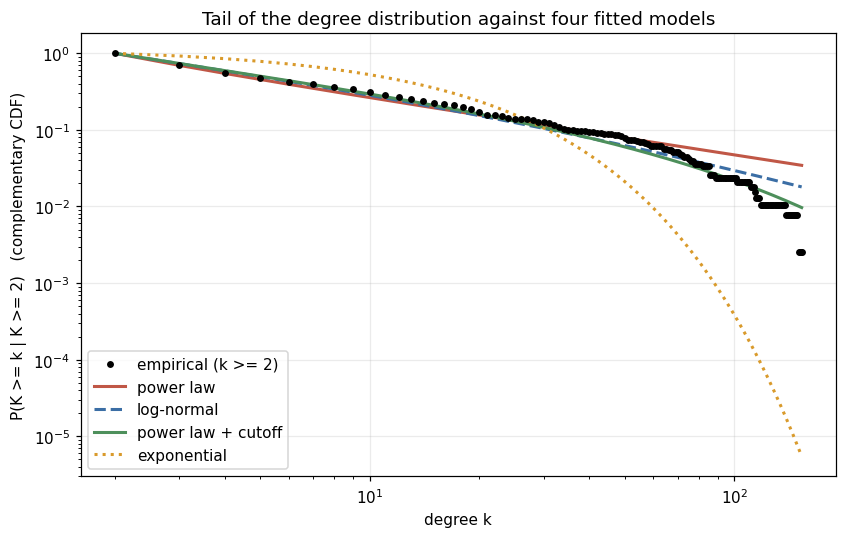

cutoff model: alpha = 1.506, lambda = 0.0069  ->  cutoff scale 1/lambda = 144 connections (largest observed degree: 153)


In [12]:
kgrid = np.arange(2, x.max() + 1)
tail = x[x >= 2]
emp = np.array([(tail >= k).mean() for k in kgrid])

fig, ax = plt.subplots(figsize=(7.8, 5))
ax.loglog(kgrid, emp, "o", color="black", ms=3.5, label="empirical (k >= 2)", zorder=5)
styles = {"power law": (RED, "-"), "log-normal": (BLUE, "--"), "power law + cutoff": (GREEN, "-"), "exponential": (ORANGE, ":")}
for name, (c, ls) in styles.items():
    ax.loglog(kgrid, pt.model_ccdf(name, models[name]["params"], 2, kgrid), color=c, ls=ls, lw=2, label=name)
ax.set_xlabel("degree k"); ax.set_ylabel("P(K >= k | K >= 2)   (complementary CDF)")
ax.set_title("Tail of the degree distribution against four fitted models"); ax.legend()
plt.tight_layout(); plt.show()
lam = models["power law + cutoff"]["params"]["lambda"]
print(f"cutoff model: alpha = {models['power law + cutoff']['params']['alpha']:.3f}, lambda = {lam:.4f}  ->  cutoff scale 1/lambda = {1/lam:.0f} connections (largest observed degree: {x.max()})")

**Reading the table and the figure.**
- The pure power law is **decisively better than an exponential** (R about 151): the tail is genuinely heavy, so "hub-dominated" is right.
- The **log-normal** and the **power law with exponential cutoff** are both significantly better than the pure power law. The cutoff model has the best AIC, and its cutoff scale (1/lambda, printed above) is about 144 connections, essentially the size of the largest hub (153). That matches the physical fact from Part B that no airport can have more than N - 1 connections.
- In the CCDF figure the pure power law (red) lies *above* the data at high degree and the cutoff model follows it, the visual signature of a truncated tail.
- Our likelihoods agree with the package's discrete results to all printed digits (cross-check line).

## Part D. Verdict on the paper's claims

Numbers below are the ones computed in this notebook (the check cell after this table pulls them straight from the results).

In [13]:
disc_lo, disc_hi = np.percentile(boot_d[:, 0], [2.5, 97.5])
ln_row = lr[lr.model == "log-normal"].iloc[0]; cut_row = lr[lr.model == "power law + cutoff"].iloc[0]
verdict_tbl = pd.DataFrame([
    ("Fitted gamma is 1.89",
     f"Reproduced: {fit_pkg.alpha:.3f} (package default, x_min = {int(fit_pkg.xmin)})", "reproduced"),
    ("That recipe is a sound estimator",
     f"No: a continuous MLE on integer data overestimates gamma (synthetic bias +0.10 to +0.66); the discrete MLE gives {d_disc['alpha']:.2f}", "weakness"),
    ("gamma at most 2, so 'anomalous regime'",
     f"Discrete estimate {d_disc['alpha']:.2f} is below 2, but the 95% bootstrap interval is [{disc_lo:.2f}, {disc_hi:.2f}] and the estimate passes 2 once x_min reaches {x_cross}; the label is not firmly established", "weakly supported"),
    ("The degree distribution 'closely follows' a power law",
     f"Rejected: goodness-of-fit p = {gof['p']:.3f}; log-normal (p = {ln_row['p-value']:.3f}) and power law with cutoff (p = {cut_row['p-value']:.4f}) both fit significantly better", "not supported"),
    ("Hub-dominated, heavy-tailed, hub-and-spoke",
     "Supported: the power law beats an exponential by a huge margin; ATL has 153 connections against a median of 3", "supported"),
    ("k_max ~ N (hub grows linearly with size)",
     "Cannot be tested from one network; a pure power law would exceed N - 1 (Part B). Revisited in M10 with several countries", "untestable here"),
], columns=["paper's claim", "what we find", "status"])
verdict_tbl.style.hide(axis="index").format(escape="html").set_properties(subset=["paper's claim", "what we find"], **{"text-align": "left", "white-space": "normal"})

paper's claim,what we find,status
Fitted gamma is 1.89,"Reproduced: 1.894 (package default, x_min = 2)",reproduced
That recipe is a sound estimator,No: a continuous MLE on integer data overestimates gamma (synthetic bias +0.10 to +0.66); the discrete MLE gives 1.73,weakness
"gamma at most 2, so 'anomalous regime'","Discrete estimate 1.73 is below 2, but the 95% bootstrap interval is [1.68, 2.35] and the estimate passes 2 once x_min reaches 12; the label is not firmly established",weakly supported
The degree distribution 'closely follows' a power law,Rejected: goodness-of-fit p = 0.001; log-normal (p = 0.012) and power law with cutoff (p = 0.0000) both fit significantly better,not supported
"Hub-dominated, heavy-tailed, hub-and-spoke",Supported: the power law beats an exponential by a huge margin; ATL has 153 connections against a median of 3,supported
k_max ~ N (hub grows linearly with size),Cannot be tested from one network; a pure power law would exceed N - 1 (Part B). Revisited in M10 with several countries,untestable here


**Why this matters for the rest of the project.** The paper's central conclusion, that the network is **robust to random failure but fragile to targeted attack**, is established by *simulation* (Section 5), not by the power-law fit, so it does not depend on the fit being right. What the fit analysis changes is the *explanation*: the network is hub-dominated and heavy-tailed with a finite-size cutoff, rather than a textbook scale-free network. We will test the attack claims directly in M5 and M6.

## Check against the paper

In [14]:
check = pd.DataFrame([
    ("gamma, rounded to 2 decimals", 1.89, round(fit_pkg.power_law.alpha, 2)),
    ("Anomalous-regime label (gamma at most 2)", True, bool(fit_pkg.power_law.alpha <= 2)),
    ("Own implementation == package (alpha)", True, bool(abs(fit_own["alpha"] - fit_pkg.alpha) < 1e-9)),
    ("Own implementation == package (x_min)", True, bool(fit_own["xmin"] == fit_pkg.xmin)),
], columns=["quantity", "paper / expected", "ours"])
check["match"] = ["OK" if a == b else "DIFF" for a, b in zip(check.iloc[:, 1], check.iloc[:, 2])]
display(check)

assert round(fit_pkg.power_law.alpha, 2) == 1.89
assert abs(fit_own["alpha"] - fit_pkg.alpha) < 1e-9 and fit_own["xmin"] == fit_pkg.xmin == 2.0
d_pkg = powerlaw.Fit(x, discrete=True, verbose=False)
assert abs(d_pkg.power_law.alpha - d_disc["alpha"]) < 1e-3 and d_pkg.power_law.xmin == d_disc["xmin"]     # our discrete MLE == package
assert 1.5 < d_disc["alpha"] < 1.9 and d_disc["alpha"] < fit_pkg.alpha                                      # discrete estimate is lower
assert (valid["continuous: bias"] > 0.05).all() and (valid["discrete: bias"].abs() < 0.05).all()           # recipe bias shown
assert abs(R_exp_own - R_exp_pkg) < 1e-3 and abs(R_ln_own - R_ln_pkg) < 1e-3                               # own LR tests == package
assert R_exp_own > 100                                                                                      # power law beats exponential
assert ln_row["R (PL vs model)"] < 0 and ln_row["p-value"] < 0.05                                           # log-normal beats PL
assert cut_row["R (PL vs model)"] < 0 and cut_row["p-value"] < 0.05                                         # cutoff beats pure PL
assert lr.loc[lr["delta AIC"] == 0, "model"].iloc[0] == "power law + cutoff"                                # best AIC
assert gof["p"] < 0.1                                                                                       # pure power law rejected
assert (res_b["expected # such airports"] > 1).all()
assert disc_lo < d_disc["alpha"] < disc_hi
print("All M2 assertions passed.")

,quantity,paper / expected,ours,match
0,"gamma, rounded to 2 decimals",1.89,1.89,OK
1,Anomalous-regime label (gamma at most 2),True,True,OK
2,Own implementation == package (alpha),True,True,OK
3,Own implementation == package (x_min),True,True,OK


All M2 assertions passed.


## Summary and take-aways

- **Reproduced:** gamma = 1.894 (paper 1.89), obtained by `powerlaw.Fit(degrees)` with defaults: continuous MLE on the tail k >= 2 (387 airports, 72%).
- **The recipe is flawed but the flaw is quantifiable.** Continuous estimators overestimate gamma on integer data; validated on synthetic data with known exponent. The correct (discrete) estimate on the same tail is about 1.73. The paper never states the method, the x_min, or any uncertainty.
- **gamma is not a stable property here:** it depends on x_min (it crosses 2 at x_min = 12) and its bootstrap interval is wide (about 1.68 to 2.35), so the "anomalous regime" label is only weakly supported.
- **"Power law" is the wrong model.** A goodness-of-fit test rejects a pure power law (p = 0.001); a power law with an exponential cutoff (cutoff scale about 144 connections, close to the largest hub) and a log-normal both fit significantly better, and a pure power law would predict airports with more connections than there are airports. The network is **heavy-tailed and hub-dominated with a finite-size cutoff**, which is a precise version of what the paper means.
- **Nothing downstream breaks:** the paper's attack and cascade results are simulations, so they stand or fall on their own. We test them in M5 and M6.

**Next:** M3 reproduces Section 4.2: Louvain and label-propagation communities (Tables 1 and 2, Figs. 4 to 6), with extra baselines, stability and ground-truth validation.